In [1]:

import torch
import platform

print("===== P3 PROJECT ENVIRONMENT =====")
print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ), "GB")
else:
    print("WARNING: GPU is not available. Check runtime settings.")


===== P3 PROJECT ENVIRONMENT =====
Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
GPU Available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [2]:

%pip install -q diffusers transformers accelerate safetensors
%pip install -q opencv-python-headless pillow
%pip install -q flask flask-cors pyngrok
%pip install -q psutil pandas matplotlib


In [3]:

import os

project_path = "/content/P3_Project"

folders = [
    "models",
    "outputs",
    "results",
    "static",
    "templates",
    "evaluation",
    "utils"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("PROJECT STRUCTURE CREATED SUCCESSFULLY!")

for folder in folders:
    print("Created:", folder)


PROJECT STRUCTURE CREATED SUCCESSFULLY!
Created: models
Created: outputs
Created: results
Created: static
Created: templates
Created: evaluation
Created: utils


In [4]:
from google.colab import drive
import os

try:
    print("Attempting to mount Google Drive...")
    drive.mount('/content/drive', force_remount=True)
    print("Google Drive connected successfully!")
except Exception as e:
    print(f"Google Drive mount failed: {e}")
    print("Proceeding with local workspace storage inside '/content/P3_Project'.")


Attempting to mount Google Drive...
Mounted at /content/drive
Google Drive connected successfully!


In [5]:

import shutil
import os

drive_project = "/content/drive/MyDrive/P3_AI_Image_Generator"

os.makedirs(drive_project, exist_ok=True)

print("Project backup folder:", drive_project)


Project backup folder: /content/drive/MyDrive/P3_AI_Image_Generator


In [6]:

import torch
import diffusers
import transformers
import cv2

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("OpenCV:", cv2.__version__)

print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.14.1+cu130
Diffusers: 0.42.1
Transformers: 5.22.1
OpenCV: 4.14.0
GPU: Tesla T4


In [7]:

import torch
from diffusers import AutoPipelineForText2Image

MODEL_ID = "stabilityai/sd-turbo"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print("Loading SD-Turbo...")
print("Device:", device)
print("Precision:", dtype)

pipe = AutoPipelineForText2Image.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    variant="fp16" if device == "cuda" else None
)

pipe = pipe.to(device)

print("SD-Turbo loaded successfully!")


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading SD-Turbo...
Device: cuda
Precision: torch.float16


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


SD-Turbo loaded successfully!


  0%|          | 0/1 [00:00<?, ?it/s]

Image generated successfully!
Generation time: 3.37 seconds


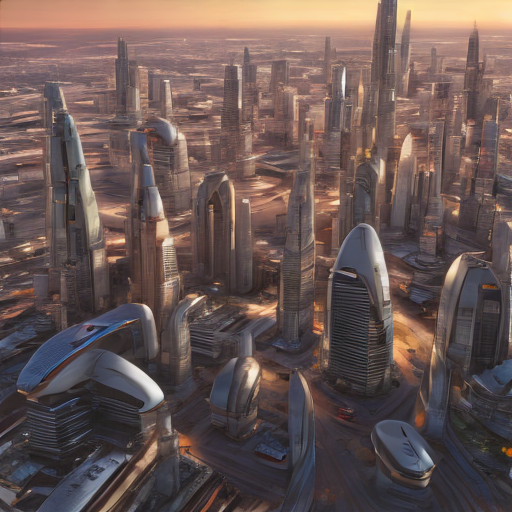

In [8]:

import time
from IPython.display import display

prompt = "A beautiful futuristic city at sunset, flying cars, cinematic lighting, highly detailed"

start_time = time.time()

image = pipe(
    prompt=prompt,
    num_inference_steps=1,
    guidance_scale=0.0,
    height=512,
    width=512
).images[0]

generation_time = time.time() - start_time

print("Image generated successfully!")
print("Generation time:", round(generation_time, 2), "seconds")

display(image)

image.save("/content/P3_Project/outputs/first_generated_image.png")


In [9]:

import os
import shutil

os.makedirs(drive_project + "/outputs", exist_ok=True)

shutil.copy(
    "/content/P3_Project/outputs/first_generated_image.png",
    drive_project + "/outputs/first_generated_image.png"
)

print("First AI image saved to Google Drive!")


First AI image saved to Google Drive!


In [10]:

import torch
import time
import pandas as pd
import matplotlib.pyplot as plt
import os

print("Benchmarking environment ready!")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


Benchmarking environment ready!
GPU: Tesla T4


In [11]:

def generate_and_measure(prompt, steps, seed=42):

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        generator = torch.Generator("cuda").manual_seed(seed)
        torch.cuda.synchronize()
    else:
        generator = torch.Generator("cpu").manual_seed(seed)

    start = time.perf_counter()

    result = pipe(
        prompt=prompt,
        num_inference_steps=steps,
        guidance_scale=0.0,
        height=512,
        width=512,
        generator=generator
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    memory = (
        torch.cuda.max_memory_allocated() / (1024 ** 3)
        if torch.cuda.is_available()
        else None
    )

    return result.images[0], elapsed, memory


  0%|          | 0/4 [00:00<?, ?it/s]

BASELINE RESULTS
Generation time: 0.64 seconds
Peak GPU memory: 3.024643898010254


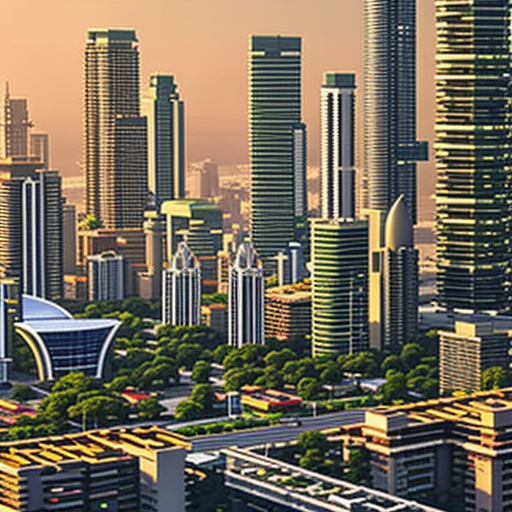

In [12]:

prompt = """
A futuristic Indian city with modern skyscrapers,
flying electric cars, green parks and beautiful sunset,
cinematic lighting, highly detailed.
"""

baseline_image, baseline_time, baseline_memory = generate_and_measure(
    prompt, steps=4
)

print("BASELINE RESULTS")
print("Generation time:", round(baseline_time, 2), "seconds")
print("Peak GPU memory:", baseline_memory)

display(baseline_image)

baseline_image.save(
    "/content/P3_Project/outputs/baseline_image.png"
)


  0%|          | 0/1 [00:00<?, ?it/s]

OPTIMIZED RESULTS
Generation time: 0.35 seconds
Peak GPU memory: 3.024643898010254


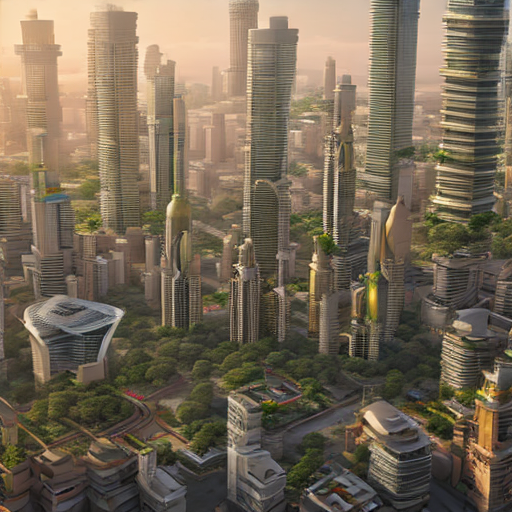

In [13]:

optimized_image, optimized_time, optimized_memory = generate_and_measure(
    prompt, steps=1
)

print("OPTIMIZED RESULTS")
print("Generation time:", round(optimized_time, 2), "seconds")
print("Peak GPU memory:", optimized_memory)

display(optimized_image)

optimized_image.save(
    "/content/P3_Project/outputs/optimized_image.png"
)


In [14]:

results = pd.DataFrame({
    "Configuration": ["Baseline (4 Steps)", "Optimized (1 Step)"],
    "Generation Time (Seconds)": [
        baseline_time, optimized_time
    ],
    "Peak GPU Memory (GB)": [
        baseline_memory, optimized_memory
    ]
})

display(results)

speed_improvement = (
    (baseline_time - optimized_time) / baseline_time
) * 100

print("Time reduction:", round(speed_improvement, 2), "%")


,Configuration,Generation Time (Seconds),Peak GPU Memory (GB)
0,Baseline (4 Steps),0.638721,3.024644
1,Optimized (1 Step),0.352314,3.024644


Time reduction: 44.84 %


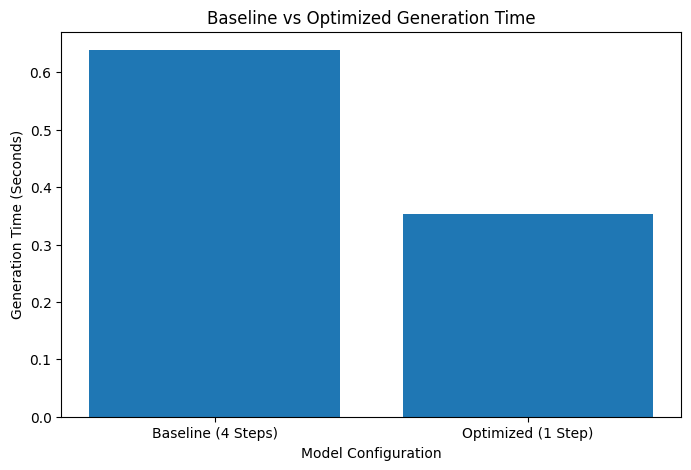

In [15]:

plt.figure(figsize=(8, 5))

plt.bar(
    results["Configuration"],
    results["Generation Time (Seconds)"]
)

plt.title("Baseline vs Optimized Generation Time")
plt.ylabel("Generation Time (Seconds)")
plt.xlabel("Model Configuration")
plt.show()


In [16]:

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("Image processing environment ready!")


OpenCV Version: 4.14.0
Image processing environment ready!


In [17]:

def enhance_image(pil_image):

    # Convert PIL image to OpenCV format
    image = np.array(pil_image)
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

    # Resize image
    resized = cv2.resize(
        image, (512, 512),
        interpolation=cv2.INTER_LANCZOS4
    )

    # Colour and contrast enhancement
    lab = cv2.cvtColor(resized, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    enhanced = cv2.merge((enhanced_l, a, b))
    enhanced = cv2.cvtColor(
        enhanced, cv2.COLOR_LAB2BGR
    )

    # Edge-aware enhancement
    filtered = cv2.bilateralFilter(
        enhanced, 7, 50, 50
    )

    # Convert back to PIL
    final_image = cv2.cvtColor(
        filtered, cv2.COLOR_BGR2RGB
    )

    return Image.fromarray(final_image)


print("Image enhancement function created!")


Image enhancement function created!


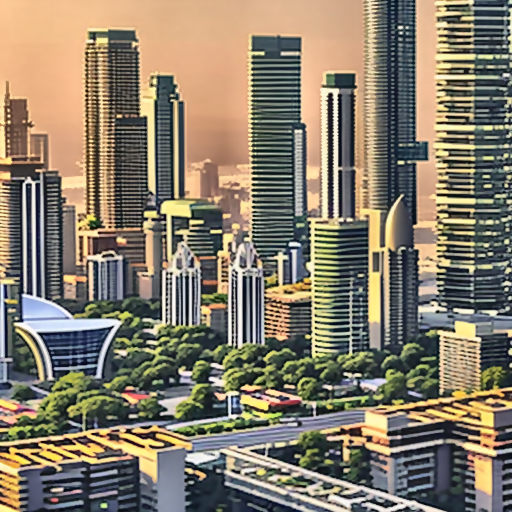

Image enhancement completed!


In [18]:

enhanced_image = enhance_image(baseline_image)

display(enhanced_image)

enhanced_image.save(
    "/content/P3_Project/outputs/enhanced_image.png"
)

print("Image enhancement completed!")


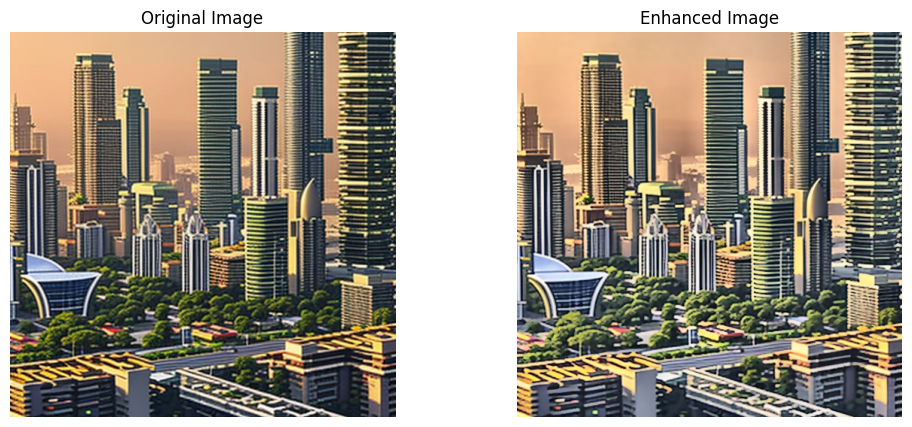

In [19]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(baseline_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_image)
plt.title("Enhanced Image")
plt.axis("off")

plt.show()


In [20]:

%pip install -q transformers

import torch
from transformers import CLIPProcessor, CLIPModel
from PIL import Image

print("CLIP libraries ready!")


CLIP libraries ready!


In [21]:

CLIP_MODEL = "openai/clip-vit-base-patch32"

clip_device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL
).to(clip_device)

clip_processor = CLIPProcessor.from_pretrained(
    CLIP_MODEL
)

clip_model.eval()

print("CLIP model loaded successfully!")
print("Device:", clip_device)


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully!
Device: cuda


In [22]:

def calculate_clip_similarity(text, pil_image):

    inputs = clip_processor(
        text=[text],
        images=pil_image,
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(clip_device)

    with torch.no_grad():
        outputs = clip_model(**inputs)

        image_features = outputs.image_embeds
        text_features = outputs.text_embeds

        image_features = image_features / image_features.norm(
            dim=-1, keepdim=True
        )

        text_features = text_features / text_features.norm(
            dim=-1, keepdim=True
        )

        similarity = (
            image_features @ text_features.T
        ).item()

    return similarity


print("CLIP evaluation function created!")


CLIP evaluation function created!


In [23]:

baseline_score = calculate_clip_similarity(
    prompt, baseline_image
)

optimized_score = calculate_clip_similarity(
    prompt, optimized_image
)

enhanced_score = calculate_clip_similarity(
    prompt, enhanced_image
)

print("===== CLIP EVALUATION RESULTS =====")

print("Baseline CLIP Score:", round(baseline_score, 4))
print("Optimized CLIP Score:", round(optimized_score, 4))
print("Enhanced CLIP Score:", round(enhanced_score, 4))


===== CLIP EVALUATION RESULTS =====
Baseline CLIP Score: 0.3362
Optimized CLIP Score: 0.3204
Enhanced CLIP Score: 0.3412


,Image,CLIP Similarity
0,Baseline,0.336152
1,Optimized,0.320434
2,Enhanced,0.341247


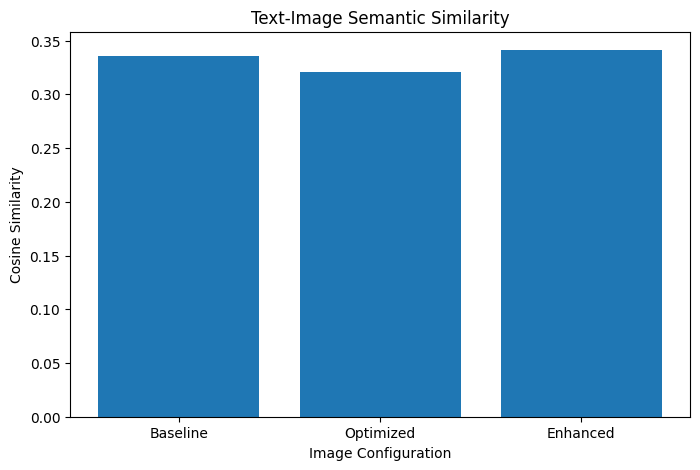

CLIP results saved successfully!


In [24]:

clip_results = pd.DataFrame({
    "Image": ["Baseline", "Optimized", "Enhanced"],
    "CLIP Similarity": [
        baseline_score,
        optimized_score,
        enhanced_score
    ]
})

display(clip_results)

plt.figure(figsize=(8, 5))

plt.bar(
    clip_results["Image"],
    clip_results["CLIP Similarity"]
)

plt.title("Text-Image Semantic Similarity")
plt.xlabel("Image Configuration")
plt.ylabel("Cosine Similarity")
plt.show()

clip_results.to_csv(
    "/content/P3_Project/results/clip_results.csv",
    index=False
)

print("CLIP results saved successfully!")


In [25]:

import cv2
import numpy as np
import pandas as pd
from PIL import Image

print("Artifact detection environment ready!")


Artifact detection environment ready!


In [26]:

def detect_image_artifacts(pil_image):

    image = np.array(pil_image.convert("RGB"))
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Blur estimation using Laplacian variance
    blur_score = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    # Edge detection
    edges = cv2.Canny(gray, 100, 200)
    edge_density = np.mean(edges > 0)

    # Noise estimation using high-frequency residual
    smooth = cv2.GaussianBlur(gray, (3, 3), 0)
    residual = gray.astype(np.float32) - smooth.astype(np.float32)
    noise_score = float(np.std(residual))

    return {
        "blur_score": float(blur_score),
        "edge_density": float(edge_density),
        "noise_score": noise_score,
        "possible_blur": bool(blur_score < 50),
        "possible_noise": bool(noise_score > 15)
    }


artifact_results = detect_image_artifacts(baseline_image)

print("ARTIFACT ANALYSIS")
for key, value in artifact_results.items():
    print(key, ":", value)


ARTIFACT ANALYSIS
blur_score : 1580.092603587531
edge_density : 0.23426437377929688
noise_score : 9.642641067504883
possible_blur : False
possible_noise : False


Correction report:
{'blur_score': 1580.092603587531, 'edge_density': 0.23426437377929688, 'noise_score': 9.642641067504883, 'possible_blur': False, 'possible_noise': False}


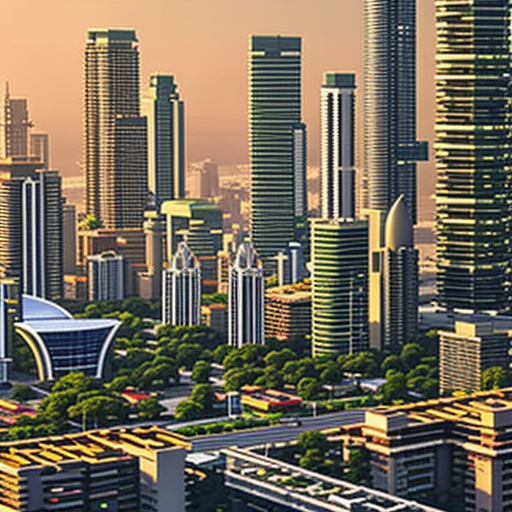

In [27]:

def correct_image_artifacts(pil_image):

    analysis = detect_image_artifacts(pil_image)

    image = np.array(pil_image.convert("RGB"))

    if analysis["possible_noise"]:
        image = cv2.bilateralFilter(
            image, 5, 30, 30
        )

    if analysis["possible_blur"]:
        blurred = cv2.GaussianBlur(image, (0, 0), 1.0)
        image = cv2.addWeighted(
            image, 1.5, blurred, -0.5, 0
        )

    corrected = Image.fromarray(image)

    return corrected, analysis


corrected_image, correction_report = correct_image_artifacts(
    baseline_image
)

print("Correction report:")
print(correction_report)

display(corrected_image)

corrected_image.save(
    "/content/P3_Project/outputs/corrected_image.png"
)


In [28]:

def get_available_resources():

    resources = {
        "device": "CPU",
        "total_gpu_memory_gb": 0,
        "free_gpu_memory_gb": 0
    }

    if torch.cuda.is_available():

        free_memory, total_memory = torch.cuda.mem_get_info()

        resources["device"] = torch.cuda.get_device_name(0)
        resources["total_gpu_memory_gb"] = round(
            total_memory / (1024 ** 3), 2
        )
        resources["free_gpu_memory_gb"] = round(
            free_memory / (1024 ** 3), 2
        )

    return resources


resources = get_available_resources()

print("RESOURCE INFORMATION")
for key, value in resources.items():
    print(key, ":", value)


RESOURCE INFORMATION
device : Tesla T4
total_gpu_memory_gb : 14.56
free_gpu_memory_gb : 10.77


In [29]:

def select_adaptive_settings():

    resources = get_available_resources()

    if not torch.cuda.is_available():
        return {
            "resolution": 256,
            "steps": 1,
            "mode": "CPU fallback"
        }

    free_memory = resources["free_gpu_memory_gb"]

    if free_memory >= 8:
        return {
            "resolution": 512,
            "steps": 4,
            "mode": "High resource mode"
        }

    elif free_memory >= 4:
        return {
            "resolution": 384,
            "steps": 2,
            "mode": "Balanced mode"
        }

    else:
        return {
            "resolution": 256,
            "steps": 1,
            "mode": "Low resource mode"
        }


settings = select_adaptive_settings()

print("ADAPTIVE GENERATION SETTINGS")

for key, value in settings.items():
    print(key, ":", value)


ADAPTIVE GENERATION SETTINGS
resolution : 512
steps : 4
mode : High resource mode


Selected mode: High resource mode
Resolution: 512
Sampling steps: 4


  0%|          | 0/4 [00:00<?, ?it/s]

Generation completed!
Time: 0.62 seconds


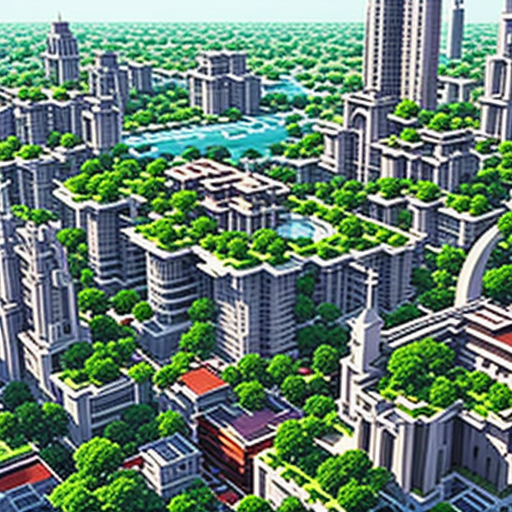

In [30]:

import time

def adaptive_generate(prompt):

    settings = select_adaptive_settings()

    resolution = settings["resolution"]
    steps = settings["steps"]

    print("Selected mode:", settings["mode"])
    print("Resolution:", resolution)
    print("Sampling steps:", steps)

    start = time.perf_counter()

    result = pipe(
        prompt=prompt,
        num_inference_steps=steps,
        guidance_scale=0.0,
        height=resolution,
        width=resolution
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    generated_image = result.images[0]

    print("Generation completed!")
    print("Time:", round(elapsed, 2), "seconds")

    return generated_image, settings, elapsed


adaptive_image, adaptive_settings, adaptive_time = adaptive_generate(
    "A beautiful futuristic Indian city with green buildings and flying cars"
)

display(adaptive_image)

adaptive_image.save(
    "/content/P3_Project/outputs/adaptive_image.png"
)


In [31]:

import json
import os
import shutil

phase6_results = {
    "artifact_analysis": correction_report,
    "adaptive_settings": adaptive_settings,
    "adaptive_generation_time": adaptive_time
}

result_path = "/content/P3_Project/results/phase6_results.json"

with open(result_path, "w") as file:
    json.dump(phase6_results, file, indent=4)

if os.path.exists(drive_project):
    shutil.copy(
        result_path,
        drive_project + "/phase6_results.json"
    )

print("Phase 6 results saved!")


Phase 6 results saved!


In [32]:

from flask import Flask, request, jsonify
from flask_cors import CORS
from PIL import Image
import torch
import time
import io
import base64
import os

app = Flask(__name__)
CORS(app)

# Health check API
@app.route("/api/health", methods=["GET"])
def health():
    return jsonify({
        "status": "success",
        "message": "P3 AI Image Generator Backend is running",
        "model": "Stable Diffusion Turbo",
        "model_loaded": pipe is not None,
        "gpu_available": torch.cuda.is_available()
    })


# Image generation API
@app.route("/api/generate", methods=["POST"])
def generate_image():

    try:
        data = request.get_json(silent=True) or {}

        prompt = data.get("prompt", "").strip()
        steps = int(data.get("steps", 1))
        resolution = int(data.get("resolution", 512))

        if not prompt:
            return jsonify({"error": "Please enter a prompt"}), 400

        if steps not in [1, 2, 3, 4]:
            return jsonify({"error": "Steps must be between 1 and 4"}), 400

        if resolution not in [256, 384, 512]:
            return jsonify({"error": "Invalid resolution"}), 400

        if pipe is None:
            return jsonify({"error": "AI model is not loaded"}), 503

        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        result = pipe(
            prompt=prompt,
            num_inference_steps=steps,
            guidance_scale=0.0,
            height=resolution,
            width=resolution
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        generation_time = time.perf_counter() - start_time

        generated_image = result.images[0]

        # Save generated image
        output_path = "/content/P3_Project/outputs"
        os.makedirs(output_path, exist_ok=True)

        filename = f"website_generated_{int(time.time())}.png"
        generated_image.save(os.path.join(output_path, filename))

        # Convert image to Base64
        buffer = io.BytesIO()
        generated_image.save(buffer, format="PNG")

        image_base64 = base64.b64encode(
            buffer.getvalue()
        ).decode("utf-8")

        memory = None

        if torch.cuda.is_available():
            memory = round(
                torch.cuda.max_memory_allocated() / (1024 ** 3), 3
            )

        return jsonify({
            "status": "success",
            "prompt": prompt,
            "image": image_base64,
            "generation_time": round(generation_time, 2),
            "gpu_memory_gb": memory,
            "steps": steps,
            "resolution": resolution,
            "filename": filename
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500


print("Flask application created successfully!")
print("Available endpoints:")
print("/api/health")
print("/api/generate")


Flask application created successfully!
Available endpoints:
/api/health
/api/generate


In [33]:

import threading
import time

def run_flask():
    app.run(
        host="0.0.0.0",
        port=5000,
        debug=False,
        use_reloader=False
    )

flask_thread = threading.Thread(
    target=run_flask,
    daemon=True
)

flask_thread.start()

time.sleep(3)

print("Flask server started!")
print("Port: 5000")


 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit


Flask server started!
Port: 5000


In [34]:

from google.colab import output
from IPython.display import display, HTML

backend_url = output.eval_js(
    "google.colab.kernel.proxyPort(5000)"
)

print("Backend URL:", backend_url)

display(HTML(
    f'<a href="{backend_url}/api/health" target="_blank">'
    '<h3>Open P3 Backend Health Check</h3></a>'
))


Backend URL: https://5000-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev


In [35]:

import requests

response = requests.post(
    backend_url + "/api/generate",
    json={
        "prompt": "A beautiful futuristic Indian city at sunset",
        "steps": 1,
        "resolution": 512
    }
)

print("Status Code:", response.status_code)

if response.status_code == 200:
    result = response.json()

    print("Image generated successfully!")
    print("Generation time:", result["generation_time"], "seconds")
    print("GPU Memory:", result["gpu_memory_gb"], "GB")
else:
    print("Error:", response.text)


Status Code: 404
Error: 


In [36]:

import requests

# Test Flask locally from inside Colab
local_url = "http://127.0.0.1:5000"

response = requests.get(
    local_url + "/api/health"
)

print("Health Check Status:", response.status_code)
print("Response:", response.text)


INFO:werkzeug:127.0.0.1 - - [07/Nov/2026 05:58:39] "GET /api/health HTTP/1.1" 200 -


Health Check Status: 200
Response: {"gpu_available":true,"message":"P3 AI Image Generator Backend is running","model":"Stable Diffusion Turbo","model_loaded":true,"status":"success"}



In [37]:

response = requests.post(
    "http://127.0.0.1:5000/api/generate",
    json={
        "prompt": "A beautiful futuristic Indian city with flying cars at sunset",
        "steps": 1,
        "resolution": 512
    }
)

print("Status:", response.status_code)

if response.status_code == 200:
    result = response.json()

    print("Image generated successfully!")
    print("Generation time:", result["generation_time"])
    print("GPU Memory:", result["gpu_memory_gb"])

else:
    print("Error:", response.text)


  0%|          | 0/1 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [07/Nov/2026 05:58:41] "POST /api/generate HTTP/1.1" 200 -


Status: 200
Image generated successfully!
Generation time: 0.9
GPU Memory: 3.599


In [38]:

import os

website_folder = "/content/P3_Project/templates"
os.makedirs(website_folder, exist_ok=True)

html_code = r"""
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>ImagineAI - Text to Image Generator</title>

<style>
* {
    margin: 0;
    padding: 0;
    box-sizing: border-box;
}

body {
    font-family: Arial, sans-serif;
    background: #f6f3ff;
    color: #25213b;
}

header {
    padding: 22px 7%;
    display: flex;
    justify-content: space-between;
    align-items: center;
    background: white;
    box-shadow: 0 2px 12px #0000000d;
}

.logo {
    font-size: 25px;
    font-weight: bold;
    color: #7651d6;
}

header span {
    color: #777;
    font-size: 13px;
}

.hero {
    text-align: center;
    padding: 55px 15px 30px;
}

.hero h1 {
    font-size: 38px;
    margin-bottom: 12px;
}

.hero h1 span {
    color: #7955dc;
}

.hero p {
    color: #777;
    line-height: 1.6;
}

.container {
    max-width: 1000px;
    margin: 15px auto 60px;
    padding: 0 20px;
}

.panel {
    background: white;
    padding: 28px;
    border-radius: 18px;
    box-shadow: 0 8px 35px #44336612;
}

label {
    display: block;
    font-weight: bold;
    margin-bottom: 10px;
}

textarea {
    width: 100%;
    height: 115px;
    padding: 15px;
    border: 1px solid #ddd5ef;
    border-radius: 12px;
    resize: vertical;
    font-size: 15px;
    outline-color: #7955dc;
}

.settings {
    display: flex;
    gap: 20px;
    margin: 20px 0;
}

.settings div {
    flex: 1;
}

select {
    width: 100%;
    padding: 12px;
    border: 1px solid #ddd5ef;
    border-radius: 9px;
    background: white;
}

button {
    border: none;
    border-radius: 10px;
    padding: 14px 25px;
    background: #7955dc;
    color: white;
    font-size: 16px;
    font-weight: bold;
    cursor: pointer;
    transition: .2s;
}

button:hover {
    background: #6040b8;
}

#generateBtn {
    width: 100%;
}

button:disabled {
    opacity: .6;
    cursor: wait;
}

#status {
    text-align: center;
    margin: 18px 0;
    color: #7955dc;
}

.result {
    margin-top: 28px;
    display: none;
}

.result img {
    display: block;
    max-width: 100%;
    max-height: 550px;
    margin: 18px auto;
    border-radius: 12px;
}

.metrics {
    display: grid;
    grid-template-columns: repeat(2, 1fr);
    gap: 15px;
    margin: 20px 0;
}

.metric {
    background: #f6f3ff;
    padding: 18px;
    border-radius: 12px;
    text-align: center;
}

.metric h3 {
    color: #7955dc;
    margin-top: 8px;
}

.download {
    display: inline-block;
    text-decoration: none;
    background: #26213a;
    color: white;
    padding: 13px 22px;
    border-radius: 9px;
}

footer {
    text-align: center;
    padding: 25px;
    color: #888;
}

@media(max-width:600px) {
    .hero h1 { font-size: 29px; }
    .settings { flex-direction: column; }
}
</style>
</head>

<body>

<header>
    <div class="logo">ImagineAI ✦</div>
    <span>AI-Powered Image Generation</span>
</header>

<section class="hero">
    <h1>Turn Your <span>Imagination</span> Into Images</h1>
    <p>Describe your imagination. Let artificial intelligence create it.</p>
</section>

<main class="container">
<div class="panel">

    <label for="prompt">Describe your image</label>

    <textarea id="prompt"
    placeholder="Example: A futuristic Indian city with flying cars, green parks and a beautiful sunset..."></textarea>

    <div class="settings">
        <div>
            <label for="steps">Generation Steps</label>
            <select id="steps">
                <option value="1">1 Step - Fast</option>
                <option value="2">2 Steps</option>
                <option value="3">3 Steps</option>
                <option value="4">4 Steps - Detailed experiment</option>
            </select>
        </div>

        <div>
            <label for="resolution">Image Resolution</label>
            <select id="resolution">
                <option value="256">256 × 256</option>
                <option value="384">384 × 384</option>
                <option value="512" selected>512 × 512</option>
            </select>
        </div>
    </div>

    <button id="generateBtn" onclick="generateImage()">
        ✨ Generate Image
    </button>

    <div id="status"></div>

    <section class="result" id="result">
        <h2>Your Generated Image</h2>

        <img id="generatedImage" alt="AI generated image">

        <div class="metrics">
            <div class="metric">
                Generation Time
                <h3 id="generationTime">--</h3>
            </div>

            <div class="metric">
                GPU Memory
                <h3 id="gpuMemory">--</h3>
            </div>
        </div>

        <a id="downloadBtn" class="download" download="generated_image.png">
            Download Image ↓
        </a>
    </section>

</div>
</main>

<footer>
    ImagineAI | Resource-Efficient Text-to-Image Generation
</footer>

<script>
const API_BASE = "__API_BASE__";

async function generateImage() {

    const prompt = document.getElementById("prompt").value.trim();
    const steps = Number(document.getElementById("steps").value);
    const resolution = Number(document.getElementById("resolution").value);

    const button = document.getElementById("generateBtn");
    const status = document.getElementById("status");

    if (!prompt) {
        alert("Please enter an image description!");
        return;
    }

    button.disabled = true;
    button.innerText = "Generating Image...";
    status.innerText = "AI is creating your image. Please wait...";

    try {

        const response = await fetch(API_BASE + "/api/generate", {
            method: "POST",
            headers: {
                "Content-Type": "application/json"
            },
            body: JSON.stringify({
                prompt: prompt,
                steps: steps,
                resolution: resolution
            })
        });

        const data = await response.json();

        if (!response.ok) {
            throw new Error(data.error || "Image generation failed");
        }

        const imageURL = "data:image/png;base64," + data.image;

        document.getElementById("generatedImage").src = imageURL;
        document.getElementById("downloadBtn").href = imageURL;

        document.getElementById("generationTime").innerText =
            data.generation_time + " seconds";

        document.getElementById("gpuMemory").innerText =
            data.gpu_memory_gb !== null
            ? data.gpu_memory_gb + " GB"
            : "Not available";

        document.getElementById("result").style.display = "block";

        status.innerText = "Image generated successfully!";

    } catch (error) {

        status.innerText = "Error: " + error.message;

    } finally {

        button.disabled = false;
        button.innerText = "✨ Generate Image";

    }
}
</script>

</body>
</html>
"""

html_path = os.path.join(website_folder, "index.html")

with open(html_path, "w", encoding="utf-8") as file:
    file.write(html_code)

print("Website HTML created successfully!")
print("Location:", html_path)


Website HTML created successfully!
Location: /content/P3_Project/templates/index.html


In [39]:

from flask import Flask, render_template
import threading
import time

web_app = Flask(
    "P3_Website",
    template_folder="/content/P3_Project/templates"
)

@web_app.route("/")
def home():
    return render_template("index.html")

# Insert the existing Colab backend URL
with open(
    "/content/P3_Project/templates/index.html",
    "r",
    encoding="utf-8"
) as file:
    page = file.read()

page = page.replace("__API_BASE__", backend_url)

with open(
    "/content/P3_Project/templates/index.html",
    "w",
    encoding="utf-8"
) as file:
    file.write(page)

def run_website():
    web_app.run(
        host="0.0.0.0",
        port=5001,
        debug=False,
        use_reloader=False
    )

website_thread = threading.Thread(
    target=run_website,
    daemon=True
)

website_thread.start()

time.sleep(3)

print("P3 Website server started!")


 * Serving Flask app 'P3_Website'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5001
 * Running on http://172.28.0.12:5001
INFO:werkzeug:Press CTRL+C to quit


P3 Website server started!


In [40]:

from google.colab import output
from IPython.display import display, HTML

website_url = output.eval_js(
    "google.colab.kernel.proxyPort(5001)"
)

print("Your website URL:", website_url)

display(HTML(
    f'<a href="{website_url}" target="_blank">'
    '<h2>🚀 OPEN MY AI IMAGE GENERATOR WEBSITE</h2>'
    '</a>'
))


Your website URL: https://5001-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev


In [41]:

from flask import Flask, request, jsonify, render_template
import torch
import time
import io
import base64
import os

# Create one combined application
combined_app = Flask(
    "P3_Combined",
    template_folder="/content/P3_Project/templates"
)

# Home page
@combined_app.route("/")
def home():
    return render_template("index.html")


# Health check
@combined_app.route("/api/health")
def health():
    return jsonify({
        "status": "success",
        "model_loaded": pipe is not None,
        "gpu_available": torch.cuda.is_available()
    })


# Image generation
@combined_app.route("/api/generate", methods=["POST"])
def generate():

    try:
        data = request.get_json(silent=True) or {}

        prompt = data.get("prompt", "").strip()
        steps = int(data.get("steps", 1))
        resolution = int(data.get("resolution", 512))

        if not prompt:
            return jsonify({"error": "Enter a prompt"}), 400

        if steps not in [1, 2, 3, 4]:
            return jsonify({"error": "Invalid steps"}), 400

        if resolution not in [256, 384, 512]:
            return jsonify({"error": "Invalid resolution"}), 400

        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        start = time.perf_counter()

        result = pipe(
            prompt=prompt,
            num_inference_steps=steps,
            guidance_scale=0.0,
            height=resolution,
            width=resolution
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        image = result.images[0]

        os.makedirs("/content/P3_Project/outputs", exist_ok=True)

        filename = f"image_{time.time_ns()}.png"

        image.save(
            f"/content/P3_Project/outputs/{filename}"
        )

        buffer = io.BytesIO()
        image.save(buffer, format="PNG")

        encoded_image = base64.b64encode(
            buffer.getvalue()
        ).decode("utf-8")

        memory = None

        if torch.cuda.is_available():
            memory = round(
                torch.cuda.max_memory_allocated() / (1024**3), 3
            )

        return jsonify({
            "status": "success",
            "image": encoded_image,
            "generation_time": round(elapsed, 2),
            "gpu_memory_gb": memory,
            "filename": filename
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500


print("Combined Flask application created!")
print("Website and AI backend use the same server.")


Combined Flask application created!
Website and AI backend use the same server.


In [42]:

html_path = "/content/P3_Project/templates/index.html"

with open(html_path, "r", encoding="utf-8") as f:
    html = f.read()

# Use same-origin API requests
html = html.replace(
    'const API_BASE = "__API_BASE__";',
    'const API_BASE = "";'
)

# Also handle an earlier URL replacement
html = html.replace(
    f'const API_BASE = "{backend_url}";',
    'const API_BASE = "";'
)

with open(html_path, "w", encoding="utf-8") as f:
    f.write(html)

print("Website API connection updated!")


Website API connection updated!


In [43]:

import threading
import time

def run_combined_app():
    combined_app.run(
        host="0.0.0.0",
        port=5002,
        debug=False,
        use_reloader=False
    )

combined_thread = threading.Thread(
    target=run_combined_app,
    daemon=True
)

combined_thread.start()

time.sleep(3)

print("Combined server started on port 5002!")


 * Serving Flask app 'P3_Combined'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5002
 * Running on http://172.28.0.12:5002
INFO:werkzeug:Press CTRL+C to quit


Combined server started on port 5002!


In [44]:

from google.colab import output
from IPython.display import display, HTML

website_url = output.eval_js(
    "google.colab.kernel.proxyPort(5002)"
)

print("Your website:", website_url)

display(HTML(
    f'<a href="{website_url}" target="_blank">'
    '<h2>🚀 OPEN IMAGINEAI WEBSITE</h2>'
    '</a>'
))


Your website: https://5002-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev


In [45]:
import requests

try:
    response = requests.get("http://127.0.0.1:5002/")
    print("Status:", response.status_code)
    print(response.text[:500])
except Exception as e:
    print("Server error:", e)

INFO:werkzeug:127.0.0.1 - - [07/Nov/2026 05:58:51] "GET / HTTP/1.1" 200 -


Status: 200

<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>ImagineAI - Text to Image Generator</title>

<style>
* {
    margin: 0;
    padding: 0;
    box-sizing: border-box;
}

body {
    font-family: Arial, sans-serif;
    background: #f6f3ff;
    color: #25213b;
}

header {
    padding: 22px 7%;
    display: flex;
    justify-content: space-between;
    align-items: center;
    background: white;
    box-shado


In [46]:
from flask import Flask, render_template, request, jsonify
from threading import Thread
import torch
import time
import base64
import io
import os

combined_app = Flask(
    __name__,
    template_folder="/content/P3_Project/templates"
)

@combined_app.route("/")
def home():
    return render_template("index.html")

@combined_app.route("/api/health")
def health():
    return jsonify({"status": "running"})

@combined_app.route("/api/generate", methods=["POST"])
def generate():
    try:
        data = request.get_json()

        prompt = data.get("prompt", "")
        steps = int(data.get("steps", 1))
        resolution = int(data.get("resolution", 512))

        if not prompt.strip():
            return jsonify({"error": "Enter a prompt"}), 400

        start = time.time()

        result = pipe(
            prompt,
            num_inference_steps=steps,
            guidance_scale=0.0,
            height=resolution,
            width=resolution
        ).images[0]

        elapsed = round(time.time() - start, 2)

        buffer = io.BytesIO()
        result.save(buffer, format="PNG")

        image_data = base64.b64encode(
            buffer.getvalue()
        ).decode("utf-8")

        gpu_memory = (
            round(torch.cuda.max_memory_allocated() / (1024**3), 3)
            if torch.cuda.is_available() else 0
        )

        return jsonify({
            "image": image_data,
            "time": elapsed,
            "gpu_memory": gpu_memory
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500


def run_server():
    combined_app.run(
        host="0.0.0.0",
        port=5002,
        debug=False,
        use_reloader=False
    )

server_thread = Thread(target=run_server, daemon=True)
server_thread.start()

print("Flask website server starting...")

 * Serving Flask app '__main__'
Flask website server starting...
 * Debug mode: off


In [47]:
import time
import requests

time.sleep(3)

response = requests.get("http://127.0.0.1:5002/")

print("Status:", response.status_code)
print("Website:", "Working" if response.status_code == 200 else "Not working")

Address already in use
Port 5002 is in use by another program. Either identify and stop that program, or start the server with a different port.
INFO:werkzeug:127.0.0.1 - - [07/Nov/2026 05:58:54] "GET / HTTP/1.1" 200 -


Status: 200
Website: Working


In [48]:
import os

print("Checking project folder...")

for root, dirs, files in os.walk("/content/P3_Project"):
    for file in files:
        if file.endswith(".html"):
            print("HTML FILE:", os.path.join(root, file))

Checking project folder...
HTML FILE: /content/P3_Project/templates/index.html


In [49]:
import os

print(os.path.exists("/content/P3_Project/templates/index.html"))

True


In [50]:
import os

os.makedirs("/content/P3_Project/templates", exist_ok=True)

print("Templates folder created!")

Templates folder created!


In [51]:
html = """
<!DOCTYPE html>
<html>
<head>
    <title>ImagineAI - Text to Image Generator</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <style>
        body {
            font-family: Arial, sans-serif;
            background: linear-gradient(135deg, #eee5ff, #fce8f5);
            text-align: center;
            padding: 30px;
        }
        .container {
            max-width: 700px;
            margin: auto;
            background: white;
            padding: 30px;
            border-radius: 20px;
            box-shadow: 0 5px 20px #ccc;
        }
        textarea {
            width: 95%;
            height: 100px;
            padding: 12px;
            border-radius: 10px;
        }
        select, button {
            padding: 12px;
            margin: 10px;
            border-radius: 8px;
        }
        button {
            background: #8054d6;
            color: white;
            border: none;
            cursor: pointer;
        }
        img {
            max-width: 100%;
            margin-top: 20px;
            border-radius: 12px;
        }
        #status { color: #8054d6; }
    </style>
</head>
<body>
<div class="container">
    <h1>ImagineAI</h1>
    <p>Resource-Efficient Text-to-Image Generation</p>

    <textarea id="prompt" placeholder="Describe the image you want..."></textarea>
    <br>

    <label>Steps:</label>
    <select id="steps">
        <option value="1">1 Step</option>
        <option value="2">2 Steps</option>
        <option value="4">4 Steps</option>
    </select>

    <label>Resolution:</label>
    <select id="resolution">
        <option value="256">256 x 256</option>
        <option value="384">384 x 384</option>
        <option value="512" selected>512 x 512</option>
    </select>

    <br>
    <button onclick="generateImage()">Generate Image</button>

    <p id="status"></p>
    <div id="result"></div>
</div>

<script>
async function generateImage() {
    const prompt = document.getElementById("prompt").value;
    const steps = document.getElementById("steps").value;
    const resolution = document.getElementById("resolution").value;
    const status = document.getElementById("status");
    const result = document.getElementById("result");

    if (!prompt.trim()) {
        status.textContent = "Please enter a prompt.";
        return;
    }

    status.textContent = "Generating image. Please wait...";
    result.innerHTML = "";

    try {
        const response = await fetch("/api/generate", {
            method: "POST",
            headers: {"Content-Type": "application/json"},
            body: JSON.stringify({
                prompt: prompt,
                steps: steps,
                resolution: resolution
            })
        });

        const data = await response.json();

        if (!response.ok) throw new Error(data.error || "Generation failed");

        result.innerHTML = `
            <img src="data:image/png;base64,${data.image}">
            <p>Generation time: ${data.time} seconds</p>
            <p>GPU memory: ${data.gpu_memory} GB</p>
            <a download="ImagineAI.png" href="data:image/png;base64,${data.image}">
                Download Image
            </a>
        `;

        status.textContent = "Image generated successfully!";
    } catch (error) {
        status.textContent = "Error: " + error.message;
    }
}
</script>
</body>
</html>
"""

with open("/content/P3_Project/templates/index.html", "w", encoding="utf-8") as f:
    f.write(html)

print("ImagineAI website created successfully!")

ImagineAI website created successfully!


In [52]:
import requests

response = requests.get("http://127.0.0.1:5002/")
print("Status:", response.status_code)

INFO:werkzeug:127.0.0.1 - - [07/Nov/2026 05:58:54] "GET / HTTP/1.1" 200 -


Status: 200


In [53]:
import torch
from diffusers import AutoPipelineForText2Image

MODEL_ID = "stabilityai/sd-turbo"

device = "cuda" if torch.cuda.is_available() else "cpu"

dtype = torch.float16 if device == "cuda" else torch.float32

print("Loading Stable Diffusion Turbo...")

pipe = AutoPipelineForText2Image.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    variant="fp16" if device == "cuda" else None
)

pipe = pipe.to(device)

print("AI model loaded successfully!")
print("Device:", device)

Loading Stable Diffusion Turbo...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


AI model loaded successfully!
Device: cuda


  0%|          | 0/1 [00:00<?, ?it/s]

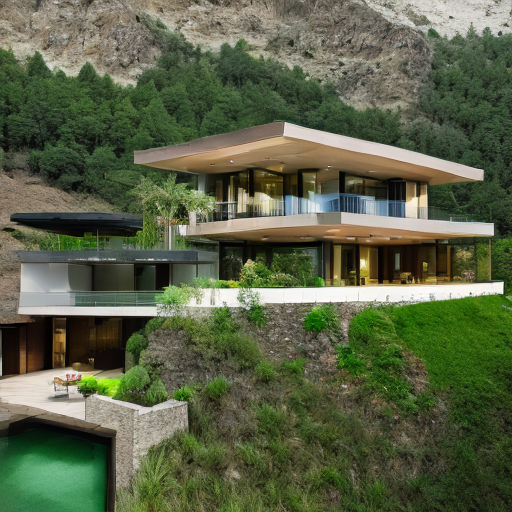

Image generation successful!


In [54]:
test_image = pipe(
    "A beautiful modern house surrounded by green mountains",
    num_inference_steps=1,
    guidance_scale=0.0,
    height=512,
    width=512
).images[0]

display(test_image)

print("Image generation successful!")


TEST 1: A beautiful modern house surrounded by green mountains


  0%|          | 0/4 [00:00<?, ?it/s]


Method: Baseline
Generation Time: 1.731 seconds
GPU Memory: 3.599 GB


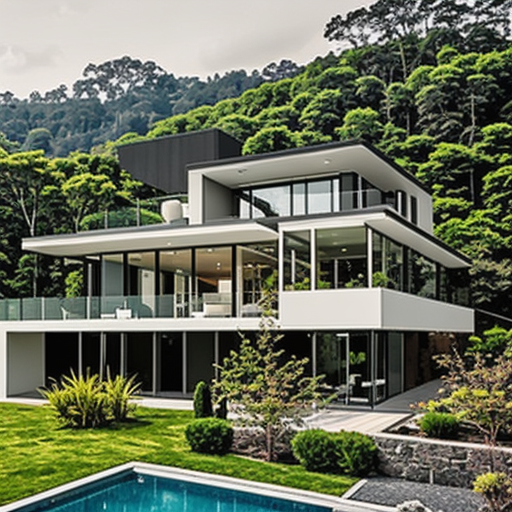

  0%|          | 0/1 [00:00<?, ?it/s]


Method: Optimized
Generation Time: 0.424 seconds
GPU Memory: 3.599 GB


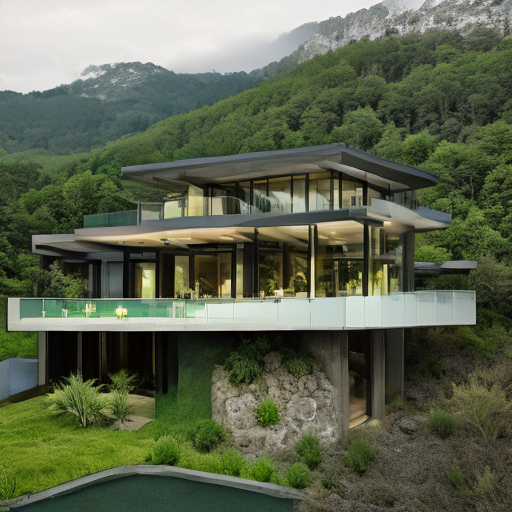


TEST 2: A golden retriever puppy playing in a flower garden


  0%|          | 0/4 [00:00<?, ?it/s]


Method: Baseline
Generation Time: 1.211 seconds
GPU Memory: 3.599 GB


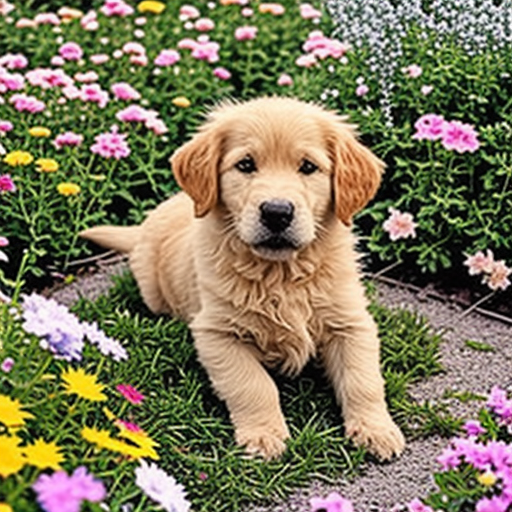

  0%|          | 0/1 [00:00<?, ?it/s]


Method: Optimized
Generation Time: 0.417 seconds
GPU Memory: 3.599 GB


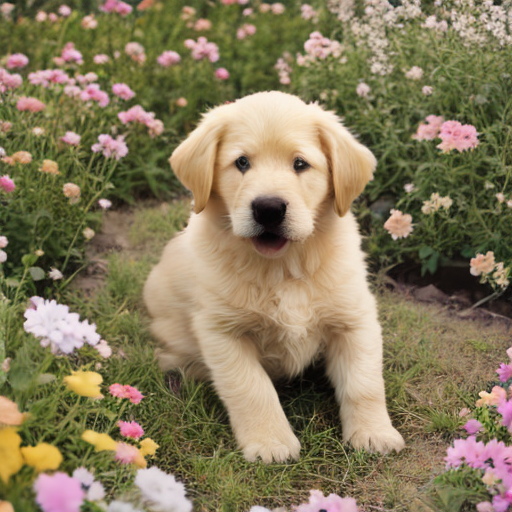


TEST 3: A futuristic city with flying cars, tall buildings and glowing lights at night


  0%|          | 0/4 [00:00<?, ?it/s]


Method: Baseline
Generation Time: 1.387 seconds
GPU Memory: 3.599 GB


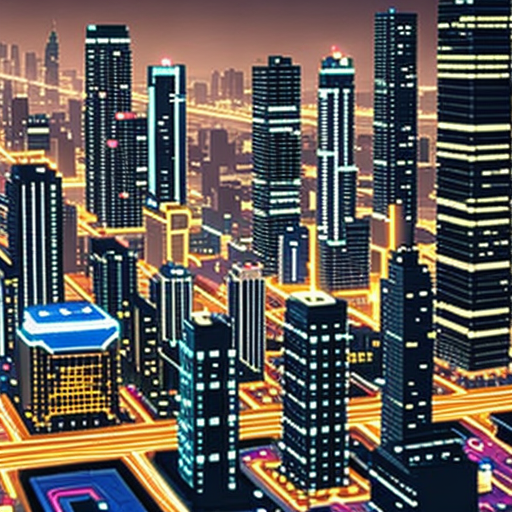

  0%|          | 0/1 [00:00<?, ?it/s]


Method: Optimized
Generation Time: 0.601 seconds
GPU Memory: 3.599 GB


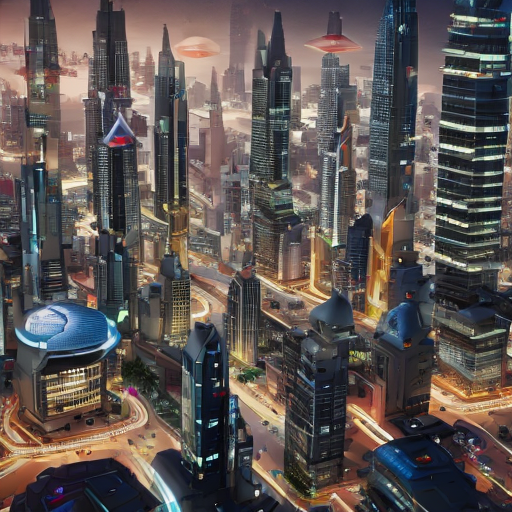


FINAL PERFORMANCE EVALUATION


,Test,Method,Steps,Generation_Time,GPU_Memory_GB,Resolution
0,1,Baseline,4,1.731,3.599,512x512
1,1,Optimized,1,0.424,3.599,512x512
2,2,Baseline,4,1.211,3.599,512x512
3,2,Optimized,1,0.417,3.599,512x512
4,3,Baseline,4,1.387,3.599,512x512
5,3,Optimized,1,0.601,3.599,512x512



Evaluation completed successfully!
CSV saved successfully!


In [55]:
import torch
import time
import pandas as pd
import os
from IPython.display import display

# Create folders
os.makedirs("/content/P3_Project/outputs/evaluation", exist_ok=True)
os.makedirs("/content/P3_Project/results", exist_ok=True)

# Three test prompts
test_prompts = [
    "A beautiful modern house surrounded by green mountains",
    "A golden retriever puppy playing in a flower garden",
    "A futuristic city with flying cars, tall buildings and glowing lights at night"
]

# Store evaluation results
evaluation_results = []

# Image generation and measurement function
def evaluate_generation(prompt, steps, test_number):

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        generator = torch.Generator(device="cuda").manual_seed(42)
        torch.cuda.synchronize()
    else:
        generator = torch.Generator().manual_seed(42)

    start_time = time.time()

    image = pipe(
        prompt,
        num_inference_steps=steps,
        guidance_scale=0.0,
        height=512,
        width=512,
        generator=generator
    ).images[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        memory = torch.cuda.max_memory_allocated() / (1024**3)
    else:
        memory = 0

    elapsed = time.time() - start_time

    # Save generated image
    filename = (
        f"/content/P3_Project/outputs/evaluation/"
        f"test_{test_number}_{steps}_steps.png"
    )

    image.save(filename)

    return image, elapsed, memory


# Run all six tests
for i, prompt in enumerate(test_prompts, start=1):

    print("\n====================================")
    print(f"TEST {i}: {prompt}")
    print("====================================")

    for mode, steps in [
        ("Baseline", 4),
        ("Optimized", 1)
    ]:

        image, elapsed, memory = evaluate_generation(
            prompt, steps, i
        )

        evaluation_results.append({
            "Test": i,
            "Method": mode,
            "Steps": steps,
            "Generation_Time": round(elapsed, 3),
            "GPU_Memory_GB": round(memory, 3),
            "Resolution": "512x512"
        })

        print("\nMethod:", mode)
        print("Generation Time:", round(elapsed, 3), "seconds")
        print("GPU Memory:", round(memory, 3), "GB")

        display(image)


# Create results table
evaluation_df = pd.DataFrame(evaluation_results)

print("\nFINAL PERFORMANCE EVALUATION")
display(evaluation_df)

# Save results
evaluation_df.to_csv(
    "/content/P3_Project/results/final_evaluation.csv",
    index=False
)

print("\nEvaluation completed successfully!")
print("CSV saved successfully!")

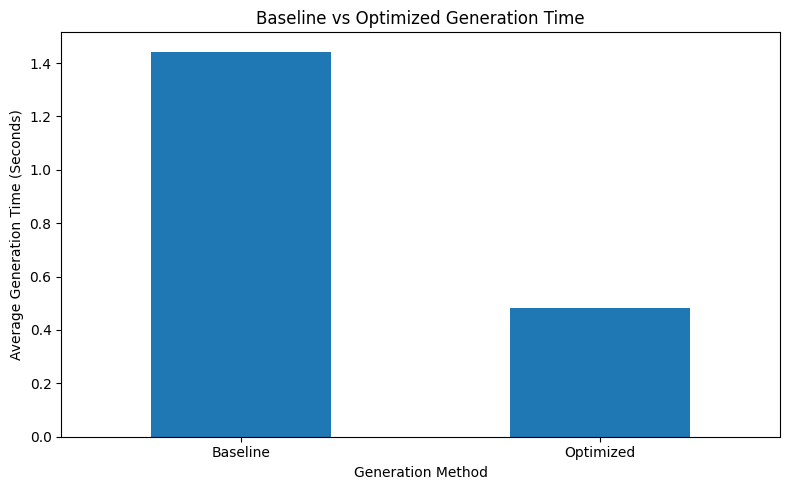

In [56]:
import matplotlib.pyplot as plt

time_comparison = evaluation_df.groupby(
    "Method"
)["Generation_Time"].mean()

plt.figure(figsize=(8, 5))

time_comparison.plot(kind="bar")

plt.title("Baseline vs Optimized Generation Time")
plt.xlabel("Generation Method")
plt.ylabel("Average Generation Time (Seconds)")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "/content/P3_Project/results/time_comparison.png"
)

plt.show()

In [57]:
baseline_time = evaluation_df[
    evaluation_df["Method"] == "Baseline"
]["Generation_Time"].mean()

optimized_time = evaluation_df[
    evaluation_df["Method"] == "Optimized"
]["Generation_Time"].mean()

improvement = (
    (baseline_time - optimized_time) / baseline_time
) * 100

print("Baseline Average:", round(baseline_time, 3), "seconds")
print("Optimized Average:", round(optimized_time, 3), "seconds")
print("Time Reduction:", round(improvement, 2), "%")

Baseline Average: 1.443 seconds
Optimized Average: 0.481 seconds
Time Reduction: 66.69 %


In [58]:
!pip install -q transformers

import torch
from transformers import CLIPProcessor, CLIPModel

clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
)

clip_processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

clip_model = clip_model.to(device)

print("CLIP model loaded successfully!")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully!


In [59]:
import torch
import pandas as pd

def calculate_clip_score(prompt, image):

    inputs = clip_processor(
        text=[prompt],
        images=image,
        return_tensors="pt",
        padding=True
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = clip_model(**inputs)

        image_features = outputs.image_embeds
        text_features = outputs.text_embeds

        image_features = image_features / image_features.norm(
            dim=-1, keepdim=True
        )

        text_features = text_features / text_features.norm(
            dim=-1, keepdim=True
        )

        similarity = (
            image_features * text_features
        ).sum(dim=-1)

    return similarity.item()


print("CLIP evaluation function ready!")

CLIP evaluation function ready!


In [60]:
from PIL import Image
import os

clip_results = []

for i, prompt in enumerate(test_prompts, start=1):

    for mode, steps in [
        ("Baseline", 4),
        ("Optimized", 1)
    ]:

        image_path = (
            f"/content/P3_Project/outputs/evaluation/"
            f"test_{i}_{steps}_steps.png"
        )

        image = Image.open(image_path).convert("RGB")

        score = calculate_clip_score(prompt, image)

        clip_results.append({
            "Test": i,
            "Method": mode,
            "CLIP_Similarity": round(score, 4)
        })

clip_df = pd.DataFrame(clip_results)

display(clip_df)

clip_df.to_csv(
    "/content/P3_Project/results/clip_evaluation.csv",
    index=False
)

print("CLIP evaluation completed!")

,Test,Method,CLIP_Similarity
0,1,Baseline,0.3108
1,1,Optimized,0.3365
2,2,Baseline,0.3752
3,2,Optimized,0.3757
4,3,Baseline,0.3234
5,3,Optimized,0.3288


CLIP evaluation completed!


In [61]:
clip_comparison = clip_df.groupby(
    "Method"
)["CLIP_Similarity"].mean()

print("Average CLIP Similarity:")
display(clip_comparison)

Average CLIP Similarity:


,CLIP_Similarity
Method,
Baseline,0.336467
Optimized,0.347000


In [62]:
import os
import shutil
from google.colab import drive

drive.mount("/content/drive")

source = "/content/P3_Project"
destination = "/content/drive/MyDrive/P3_Project"

os.makedirs(destination, exist_ok=True)

folders_to_copy = [
    "outputs",
    "results",
    "templates"
]

for folder in folders_to_copy:
    src = os.path.join(source, folder)
    dst = os.path.join(destination, folder)

    if os.path.exists(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)

print("All project files saved to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All project files saved to Google Drive!


In [63]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive/P3_Project"):
    for file in files:
        print(os.path.join(root, file))

/content/drive/MyDrive/P3_Project/templates/index.html
/content/drive/MyDrive/P3_Project/outputs/website_generated_1794031120.png
/content/drive/MyDrive/P3_Project/outputs/optimized_image.png
/content/drive/MyDrive/P3_Project/outputs/adaptive_image.png
/content/drive/MyDrive/P3_Project/outputs/enhanced_image.png
/content/drive/MyDrive/P3_Project/outputs/corrected_image.png
/content/drive/MyDrive/P3_Project/outputs/baseline_image.png
/content/drive/MyDrive/P3_Project/outputs/first_generated_image.png
/content/drive/MyDrive/P3_Project/outputs/evaluation/test_1_4_steps.png
/content/drive/MyDrive/P3_Project/outputs/evaluation/test_1_1_steps.png
/content/drive/MyDrive/P3_Project/outputs/evaluation/test_2_4_steps.png
/content/drive/MyDrive/P3_Project/outputs/evaluation/test_2_1_steps.png
/content/drive/MyDrive/P3_Project/outputs/evaluation/test_3_4_steps.png
/content/drive/MyDrive/P3_Project/outputs/evaluation/test_3_1_steps.png
/content/drive/MyDrive/P3_Project/results/final_evaluation.csv


In [64]:
!pip install -q opencv-python-headless

In [65]:
print("Model loaded:", pipe is not None)

Model loaded: True


In [66]:
html_path = "/content/P3_Project/templates/index.html"

with open(html_path, "r", encoding="utf-8") as f:
    html = f.read()

enhancer_section = """
<section style="
    margin-top:35px;
    padding:25px;
    background:#f7f0ff;
    border-radius:16px;
    text-align:center;
">
    <h2>Image to HD Enhancer</h2>
    <p>Upload a blurry image and improve its sharpness and resolution.</p>

    <input
        type="file"
        id="hdImage"
        accept="image/*"
        style="margin:15px;"
    >

    <br>

    <label>Enhancement:</label>
    <select id="hdScale">
        <option value="2">2x HD</option>
        <option value="4">4x HD</option>
    </select>

    <br>

    <button onclick="enhanceImage()">
        Enhance Image
    </button>

    <p id="hdStatus"></p>

    <div id="hdResult"></div>
</section>
"""

if 'id="hdImage"' not in html:
    closing_div = html.rfind("</div>")
    html = html[:closing_div] + enhancer_section + html[closing_div:]

enhancer_script = """
async function enhanceImage() {
    const file = document.getElementById("hdImage").files[0];
    const scale = document.getElementById("hdScale").value;
    const status = document.getElementById("hdStatus");
    const result = document.getElementById("hdResult");

    if (!file) {
        status.textContent = "Please select an image first.";
        return;
    }

    const formData = new FormData();
    formData.append("image", file);
    formData.append("scale", scale);

    status.textContent = "Enhancing image... Please wait.";
    result.innerHTML = "";

    try {
        const response = await fetch("/api/enhance", {
            method: "POST",
            body: formData
        });

        const data = await response.json();

        if (!response.ok) {
            throw new Error(data.error || "Enhancement failed");
        }

        const imageURL = "data:image/png;base64," + data.image;

        result.innerHTML = `
            <h3>Enhanced Image</h3>
            <img src="${imageURL}"
                 style="max-width:100%;border-radius:12px;">

            <p>Resolution: ${data.width} × ${data.height}</p>
            <p>Upscaling: ${data.scale}x</p>

            <a href="${imageURL}" download="ImagineAI_HD.png">
                Download HD Image
            </a>
        `;

        status.textContent = "Image enhanced successfully!";

    } catch (error) {
        status.textContent = "Error: " + error.message;
    }
}
"""

if "async function enhanceImage()" not in html:
    html = html.replace("</script>", enhancer_script + "\n</script>")

with open(html_path, "w", encoding="utf-8") as f:
    f.write(html)

print("HD Enhancer added to ImagineAI website!")

HD Enhancer added to ImagineAI website!


In [67]:
import cv2
import numpy as np
import base64
from flask import request, jsonify

@combined_app.route("/api/enhance", methods=["POST"])
def enhance_image():

    try:
        if "image" not in request.files:
            return jsonify({"error": "Please upload an image"}), 400

        uploaded_file = request.files["image"]
        scale = int(request.form.get("scale", 2))

        if scale not in [2, 4]:
            return jsonify({"error": "Choose 2x or 4x"}), 400

        # Read uploaded image
        image_bytes = uploaded_file.read()
        image_array = np.frombuffer(image_bytes, np.uint8)
        image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

        if image is None:
            return jsonify({"error": "Invalid image"}), 400

        # Resize image
        height, width = image.shape[:2]

        if max(height, width) * scale > 4096:
            return jsonify({
                "error": "Image is too large for this enhancement setting"
            }), 400

        image = cv2.resize(
            image,
            (width * scale, height * scale),
            interpolation=cv2.INTER_CUBIC
        )

        # Reduce noise
        image = cv2.bilateralFilter(image, 7, 50, 50)

        # Improve contrast
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        l = clahe.apply(l)

        image = cv2.merge((l, a, b))
        image = cv2.cvtColor(image, cv2.COLOR_LAB2BGR)

        # Sharpen image
        blurred = cv2.GaussianBlur(image, (0, 0), 2)
        image = cv2.addWeighted(
            image, 1.5,
            blurred, -0.5,
            0
        )

        # Encode enhanced image
        success, encoded = cv2.imencode(".png", image)

        if not success:
            return jsonify({"error": "Image processing failed"}), 500

        image_base64 = base64.b64encode(
            encoded.tobytes()
        ).decode("utf-8")

        return jsonify({
            "image": image_base64,
            "width": image.shape[1],
            "height": image.shape[0],
            "scale": scale
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500

In [68]:
from threading import Thread

def start_website():
    combined_app.run(
        host="0.0.0.0",
        port=5002,
        debug=False,
        use_reloader=False
    )

website_thread = Thread(target=start_website, daemon=True)
website_thread.start()

print("ImagineAI server started!")

 * Serving Flask app '__main__'
ImagineAI server started!
 * Debug mode: off


Address already in use
Port 5002 is in use by another program. Either identify and stop that program, or start the server with a different port.


In [69]:
from google.colab import output

website_url = output.eval_js(
    "google.colab.kernel.proxyPort(5002)"
)

print("OPEN YOUR IMAGINEAI WEBSITE:")
print(website_url)

OPEN YOUR IMAGINEAI WEBSITE:
https://5002-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev


In [70]:
import os
import shutil
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Project source and destination
source = "/content/P3_Project"
destination = "/content/drive/MyDrive/ImagineAI_Final_Project"

# Create destination folder
os.makedirs(destination, exist_ok=True)

# Copy complete project folder
if os.path.exists(source):

    shutil.copytree(
        source,
        destination,
        dirs_exist_ok=True
    )

    print("====================================")
    print("IMAGINEAI PROJECT SAVED SUCCESSFULLY")
    print("====================================")
    print("Location:", destination)

else:
    print("Project folder not found!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IMAGINEAI PROJECT SAVED SUCCESSFULLY
Location: /content/drive/MyDrive/ImagineAI_Final_Project


In [71]:
import os

folder = "/content/drive/MyDrive/ImagineAI_Final_Project"

print("SAVED PROJECT FILES")
print("====================")

for root, dirs, files in os.walk(folder):
    for file in files:
        path = os.path.join(root, file)
        size = os.path.getsize(path) / 1024

        print(f"{os.path.relpath(path, folder)}  ({size:.2f} KB)")

print("\nAll available files listed!")

SAVED PROJECT FILES
templates/index.html  (5.40 KB)
outputs/website_generated_1794031120.png  (391.53 KB)
outputs/optimized_image.png  (463.58 KB)
outputs/adaptive_image.png  (562.05 KB)
outputs/enhanced_image.png  (467.05 KB)
outputs/corrected_image.png  (487.71 KB)
outputs/baseline_image.png  (487.71 KB)
outputs/first_generated_image.png  (428.42 KB)
outputs/evaluation/test_1_4_steps.png  (494.68 KB)
outputs/evaluation/test_1_1_steps.png  (470.94 KB)
outputs/evaluation/test_2_4_steps.png  (550.22 KB)
outputs/evaluation/test_2_1_steps.png  (470.27 KB)
outputs/evaluation/test_3_4_steps.png  (507.14 KB)
outputs/evaluation/test_3_1_steps.png  (503.91 KB)
results/final_evaluation.csv  (0.25 KB)
results/time_comparison.png  (23.51 KB)
results/clip_evaluation.csv  (0.14 KB)
results/clip_results.csv  (0.10 KB)
results/phase6_results.json  (0.39 KB)

All available files listed!


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (78 > 77). Running this sequence through the model will result in indexing errors
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer CLIPTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['ultra realistic .']


  0%|          | 0/4 [00:00<?, ?it/s]

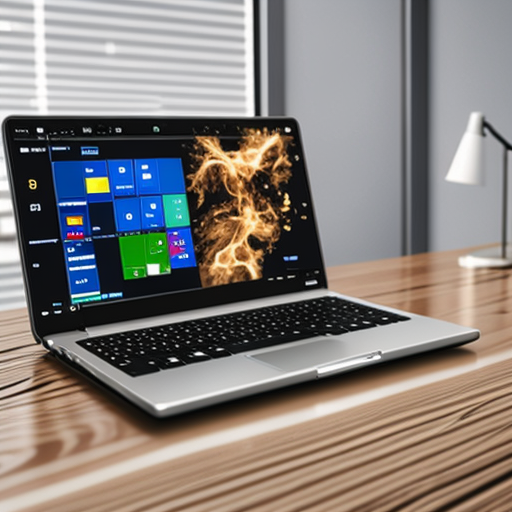

In [72]:
prompt = """
A highly detailed photorealistic 3D render of a modern laptop
on a clean futuristic computer desk, realistic metallic body,
glossy screen, detailed keyboard, realistic reflections,
soft studio lighting, ambient occlusion, ray tracing,
cinematic composition, physically based rendering,
Blender Cycles, Unreal Engine 5 quality,
sharp focus, vibrant natural colors, 3D CGI,
professional product visualization, ultra realistic.
"""

image = pipe(
    prompt,
    num_inference_steps=4,
    guidance_scale=0.0,
    height=512,
    width=512
).images[0]

display(image)

image.save(
    "/content/P3_Project/outputs/3d_laptop_render.png"
)

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: [', raw photograph , ultra realistic , high detail , natural colors , professional photography .']


  0%|          | 0/4 [00:00<?, ?it/s]

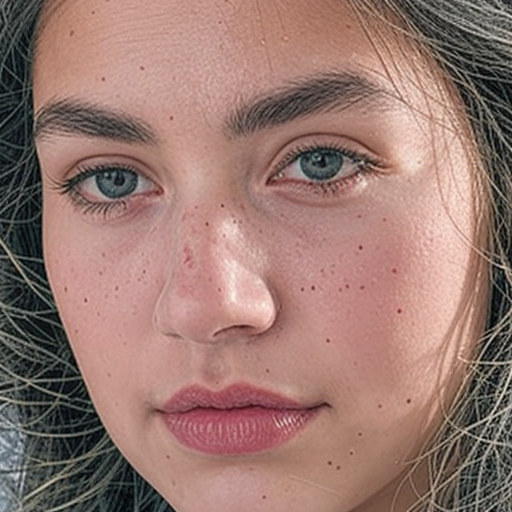

In [73]:
realistic_prompt = """
A photorealistic DSLR photograph of a beautiful young adult woman,
natural human facial features, realistic skin texture with visible
pores and tiny natural imperfections, detailed human eyes,
individual hair strands, natural eyebrows, realistic lips,
soft natural daylight, professional portrait photography,
85mm camera lens, shallow depth of field, realistic shadows,
true-to-life skin tones, RAW photograph, ultra realistic,
high detail, natural colors, professional photography.
"""

image = pipe(
    realistic_prompt,
    num_inference_steps=4,
    guidance_scale=0.0,
    height=512,
    width=512
).images[0]

display(image)

image.save(
    "/content/P3_Project/outputs/realistic_girl_test.png"
)

In [74]:
from google.colab import output

website_url = output.eval_js(
    "google.colab.kernel.proxyPort(5002)"
)

print("REALISTIC IMAGE BROWSER LINK:")
print(website_url + "/realistic-output")

REALISTIC IMAGE BROWSER LINK:
https://5002-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev/realistic-output


In [75]:
import os
from flask import Flask, send_file
from threading import Thread

image_path = "/content/P3_Project/outputs/realistic_girl_test.png"

if not os.path.exists(image_path):
    print("Image not found. Generate and save the image first.")
else:
    image_app = Flask("realistic_image_viewer")

    @image_app.route("/")
    def show_image():
        return send_file(image_path, mimetype="image/png")

    image_thread = Thread(
        target=lambda: image_app.run(
            host="0.0.0.0",
            port=5003,
            debug=False,
            use_reloader=False
        ),
        daemon=True
    )

    image_thread.start()
    print("Image viewer started!")

Image viewer started!
 * Serving Flask app 'realistic_image_viewer'
 * Debug mode: off


In [76]:
from google.colab import output

image_url = output.eval_js(
    "google.colab.kernel.proxyPort(5003)"
)

print("OPEN YOUR IMAGE HERE:")
print(image_url)

OPEN YOUR IMAGE HERE:
https://5003-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev


In [77]:
import requests

try:
    r = requests.get("http://127.0.0.1:5002/")
    print("Server status:", r.status_code)
except:
    print("Server is not running. Start your combined Flask server first.")

INFO:werkzeug:127.0.0.1 - - [07/Nov/2026 06:08:10] "GET / HTTP/1.1" 200 -


Server status: 200


In [78]:
from google.colab import output

website_url = output.eval_js(
    "google.colab.kernel.proxyPort(5002)"
)

print("IMAGINEAI WEBSITE:")
print(website_url)

IMAGINEAI WEBSITE:
https://5002-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev


In [80]:
import os
import io
import cv2
import base64
import torch
import threading
import numpy as np

from PIL import Image
from flask import Flask, request, jsonify, render_template_string
from flask import send_from_directory
from flask_cors import CORS

# ==========================================
# 1. PROJECT FOLDERS
# ==========================================

BASE_DIR = "/content/P3_Project"
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
TEMPLATE_DIR = os.path.join(BASE_DIR, "templates")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TEMPLATE_DIR, exist_ok=True)

# ==========================================
# 2. CHECK MODEL
# ==========================================

if "pipe" not in globals():
    raise RuntimeError("Stable Diffusion model is not loaded. Run your model loading cell first.")

# ==========================================
# 3. CREATE FLASK APP
# ==========================================

combined_app = Flask(__name__)
CORS(combined_app)

# ==========================================
# 4. WEBSITE HTML
# ==========================================

html = r"""
<!DOCTYPE html>
<html>
<head>
<title>ImagineAI - AI Image Generator</title>
<meta name="viewport" content="width=device-width, initial-scale=1">

<style>
* {
    box-sizing: border-box;
}

body {
    margin: 0;
    font-family: Arial, sans-serif;
    background: #111827;
    color: white;
}

header {
    padding: 22px 8%;
    background: #1f2937;
    font-size: 25px;
    font-weight: bold;
    color: #a78bfa;
}

.container {
    max-width: 950px;
    margin: 40px auto;
    padding: 25px;
}

h1 {
    text-align: center;
    font-size: 38px;
}

.subtitle {
    text-align: center;
    color: #cbd5e1;
    margin-bottom: 35px;
}

.panel {
    background: #1f2937;
    padding: 25px;
    border-radius: 15px;
}

label {
    display: block;
    margin: 18px 0 8px;
    font-weight: bold;
}

textarea, select {
    width: 100%;
    padding: 14px;
    border-radius: 9px;
    border: 1px solid #475569;
    background: #111827;
    color: white;
    font-size: 15px;
}

textarea {
    height: 110px;
    resize: vertical;
}

button {
    width: 100%;
    padding: 15px;
    margin-top: 22px;
    border: none;
    border-radius: 9px;
    background: #8b5cf6;
    color: white;
    font-size: 17px;
    font-weight: bold;
    cursor: pointer;
}

button:hover {
    background: #7c3aed;
}

button:disabled {
    opacity: 0.6;
    cursor: wait;
}

.result {
    margin-top: 30px;
    text-align: center;
}

.result img {
    max-width: 100%;
    border-radius: 12px;
    margin-top: 15px;
}

.status {
    margin-top: 20px;
    color: #c4b5fd;
    text-align: center;
}

.download {
    display: inline-block;
    padding: 12px 25px;
    margin-top: 15px;
    background: #059669;
    color: white;
    text-decoration: none;
    border-radius: 8px;
}

hr {
    border: 1px solid #374151;
    margin: 45px 0;
}

input[type=file] {
    width: 100%;
    padding: 12px;
    background: #111827;
    border-radius: 8px;
    color: white;
}

footer {
    text-align: center;
    color: #9ca3af;
    padding: 25px;
}
</style>
</head>

<body>

<header>✨ ImagineAI</header>

<div class="container">

<h1>Turn Your Imagination Into Images</h1>

<p class="subtitle">
Create AI images quickly with resource-efficient generation.
</p>

<div class="panel">

<h2>AI Image Generator</h2>

<label>Enter your image prompt</label>

<textarea id="prompt"
placeholder="Example: A realistic 3D futuristic city at sunset..."></textarea>

<label>Generation Steps</label>

<select id="steps">
<option value="1">1 Step - Fast</option>
<option value="2">2 Steps - Balanced</option>
<option value="4">4 Steps - Detailed</option>
</select>

<label>Image Resolution</label>

<select id="resolution">
<option value="256">256 × 256</option>
<option value="384">384 × 384</option>
<option value="512" selected>512 × 512</option>
</select>

<button id="generateBtn" onclick="generateImage()">
Generate Image
</button>

<div class="status" id="status"></div>

<div class="result" id="result"></div>

</div>

<hr>

<div class="panel">

<h2>Image to HD Enhancer</h2>

<p>Upload an image to improve its resolution and appearance.</p>

<label>Select Image</label>
<input type="file" id="imageFile" accept="image/*">

<label>Upscale Factor</label>

<select id="scale">
<option value="2">2× Upscale</option>
<option value="4">4× Upscale</option>
</select>

<button onclick="enhanceImage()">Enhance Image</button>

<div class="status" id="enhanceStatus"></div>

<div class="result" id="enhanceResult"></div>

</div>

</div>

<footer>ImagineAI | Resource-Efficient Text-to-Image Generation</footer>

<script>

async function generateImage() {

    const prompt = document.getElementById("prompt").value.trim();
    const steps = Number(document.getElementById("steps").value);
    const resolution = Number(document.getElementById("resolution").value);

    const status = document.getElementById("status");
    const result = document.getElementById("result");
    const button = document.getElementById("generateBtn");

    if (!prompt) {
        status.textContent = "Please enter an image prompt.";
        return;
    }

    button.disabled = true;
    button.textContent = "Generating...";
    status.textContent = "Please wait while ImagineAI creates your image...";
    result.innerHTML = "";

    try {

        const response = await fetch("/api/generate", {
            method: "POST",
            headers: {
                "Content-Type": "application/json"
            },
            body: JSON.stringify({
                prompt: prompt,
                steps: steps,
                resolution: resolution
            })
        });

        const responseText = await response.text();

        if (!responseText) {
            throw new Error("The server returned an empty response.");
        }

        let data;

        try {
            data = JSON.parse(responseText);
        } catch (error) {
            throw new Error("Invalid server response: " + responseText.slice(0, 200));
        }

        if (!response.ok || !data.success) {
            throw new Error(data.error || "Image generation failed.");
        }

        result.innerHTML = `
            <h3>Generated Image</h3>
            <img src="${data.image}" alt="Generated AI image">
            <br>
            <a class="download" href="${data.image}" download="ImagineAI.png">
                Download Image
            </a>
        `;

        status.textContent = "Image generated successfully! Time: " + data.time + " seconds";

    } catch (error) {

        status.textContent = "Error: " + error.message;
        console.error(error);

    } finally {

        button.disabled = false;
        button.textContent = "Generate Image";

    }
}


async function enhanceImage() {

    const file = document.getElementById("imageFile").files[0];
    const scale = document.getElementById("scale").value;

    const status = document.getElementById("enhanceStatus");
    const result = document.getElementById("enhanceResult");

    if (!file) {
        status.textContent = "Please select an image.";
        return;
    }

    status.textContent = "Enhancing image...";
    result.innerHTML = "";

    try {

        const formData = new FormData();
        formData.append("image", file);
        formData.append("scale", scale);

        const response = await fetch("/api/enhance", {
            method: "POST",
            body: formData
        });

        const responseText = await response.text();

        if (!responseText) {
            throw new Error("The server returned an empty response.");
        }

        let data;

        try {
            data = JSON.parse(responseText);
        } catch (error) {
            throw new Error("Invalid server response: " + responseText.slice(0, 200));
        }

        if (!response.ok || !data.success) {
            throw new Error(data.error || "Image enhancement failed.");
        }

        result.innerHTML = `
            <h3>Enhanced Image</h3>
            <img src="${data.image}" alt="Enhanced image">
            <br>
            <a class="download" href="${data.image}" download="ImagineAI_HD.png">
                Download Enhanced Image
            </a>
        `;

        status.textContent = "Image enhanced successfully!";

    } catch (error) {

        status.textContent = "Error: " + error.message;
        console.error(error);

    }
}

</script>

</body>
</html>
"""

with open(os.path.join(TEMPLATE_DIR, "index.html"), "w") as f:
    f.write(html)

# ==========================================
# 5. HOME PAGE
# ==========================================

@combined_app.route("/")
def home():
    return render_template_string(html)

# ==========================================
# 6. HEALTH CHECK
# ==========================================

@combined_app.route("/api/health")
def health():
    return jsonify({
        "success": True,
        "message": "ImagineAI backend is running"
    })

# ==========================================
# 7. IMAGE GENERATION API
# ==========================================

@combined_app.route("/api/generate", methods=["POST"])
def generate():

    import time

    try:
        data = request.get_json(silent=True) or {}

        prompt = str(data.get("prompt", "")).strip()
        steps = int(data.get("steps", 1))
        resolution = int(data.get("resolution", 512))

        if not prompt:
            return jsonify({
                "success": False,
                "error": "Please enter a prompt."
            }), 400

        if steps not in [1, 2, 4]:
            return jsonify({
                "success": False,
                "error": "Invalid generation steps."
            }), 400

        if resolution not in [256, 384, 512]:
            return jsonify({
                "success": False,
                "error": "Invalid resolution."
            }), 400

        start = time.time()

        with torch.inference_mode():

            generated = pipe(
                prompt=prompt,
                num_inference_steps=steps,
                guidance_scale=0.0,
                height=resolution,
                width=resolution
            )

        image = generated.images[0]

        filename = f"generated_{int(time.time() * 1000)}.png"
        filepath = os.path.join(OUTPUT_DIR, filename)

        image.save(filepath)

        buffer = io.BytesIO()
        image.save(buffer, format="PNG")

        image_base64 = base64.b64encode(
            buffer.getvalue()
        ).decode("utf-8")

        elapsed = round(time.time() - start, 2)

        return jsonify({
            "success": True,
            "image": "data:image/png;base64," + image_base64,
            "filename": filename,
            "time": elapsed,
            "steps": steps,
            "resolution": resolution
        })

    except Exception as e:

        import traceback
        traceback.print_exc()

        return jsonify({
            "success": False,
            "error": str(e)
        }), 500

# ==========================================
# 8. IMAGE ENHANCEMENT API
# ==========================================

@combined_app.route("/api/enhance", methods=["POST"])
def enhance():

    try:

        if "image" not in request.files:
            return jsonify({
                "success": False,
                "error": "Please upload an image."
            }), 400

        uploaded = request.files["image"]
        scale = int(request.form.get("scale", 2))

        if scale not in [2, 4]:
            return jsonify({
                "success": False,
                "error": "Scale must be 2 or 4."
            }), 400

        image_bytes = uploaded.read()
        image_array = np.frombuffer(image_bytes, np.uint8)

        img = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

        if img is None:
            return jsonify({
                "success": False,
                "error": "Invalid image file."
            }), 400

        height, width = img.shape[:2]

        enlarged = cv2.resize(
            img,
            (width * scale, height * scale),
            interpolation=cv2.INTER_CUBIC
        )

        denoised = cv2.bilateralFilter(
            enlarged, 9, 75, 75
        )

        lab = cv2.cvtColor(
            denoised, cv2.COLOR_BGR2LAB
        )

        l, a, b = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        l = clahe.apply(l)

        enhanced = cv2.merge((l, a, b))
        enhanced = cv2.cvtColor(
            enhanced, cv2.COLOR_LAB2BGR
        )

        blurred = cv2.GaussianBlur(
            enhanced, (0, 0), 1.5
        )

        sharpened = cv2.addWeighted(
            enhanced, 1.5, blurred, -0.5, 0
        )

        success, encoded = cv2.imencode(
            ".png", sharpened
        )

        if not success:
            raise RuntimeError("Could not encode enhanced image.")

        image_base64 = base64.b64encode(
            encoded.tobytes()
        ).decode("utf-8")

        return jsonify({
            "success": True,
            "image": "data:image/png;base64," + image_base64,
            "scale": scale
        })

    except Exception as e:

        import traceback
        traceback.print_exc()

        return jsonify({
            "success": False,
            "error": str(e)
        }), 500

# ==========================================
# 9. START SERVER
# ==========================================

def run_server():
    combined_app.run(
        host="0.0.0.0",
        port=5002,
        debug=False,
        use_reloader=False
    )

server_thread = threading.Thread(
    target=run_server,
    daemon=True
)

server_thread.start()

print("ImagineAI server started on port 5002")

 * Serving Flask app '__main__'
ImagineAI server started on port 5002
 * Debug mode: off


Address already in use
Port 5002 is in use by another program. Either identify and stop that program, or start the server with a different port.


In [81]:
from google.colab import output

website_url = output.eval_js(
    "google.colab.kernel.proxyPort(5002)"
)

print("OPEN YOUR IMAGINEAI WEBSITE:")
print(website_url)

OPEN YOUR IMAGINEAI WEBSITE:
https://5002-gpu-t4-s-usw4a2-12qxyhu5wtysm-a.us-west4.prod.r.colab.dev


In [82]:
import os

project_path = "/content/P3_Project"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    for file in files:
        print("  " * (level + 1) + file)

P3_Project/
  utils/
  templates/
    index.html
  evaluation/
  static/
  results/
    clip_evaluation.csv
    clip_results.csv
    final_evaluation.csv
    time_comparison.png
    phase6_results.json
  models/
  outputs/
    image_1794031852090843448.png
    image_1794031905649662115.png
    image_1794032528020920167.png
    image_1794032235262525735.png
    image_1794031795813909725.png
    image_1794035626744324804.png
    3d_laptop_render.png
    image_1794032574986902478.png
    image_1794035502792975035.png
    image_1794032007078770954.png
    image_1794032960732131433.png
    image_1794031886917581868.png
    image_1794031283251928016.png
    image_1794031765989042348.png
    image_1794035708376207593.png
    image_1794035553177554947.png
    image_1794032953002635863.png
    website_generated_1794031120.png
    image_1794031992092180189.png
    image_1794031981995818546.png
    image_1794031897985737233.png
    realistic_girl_test.png
    image_1794032000344486472.png
    ima

In [83]:
import shutil

shutil.make_archive(
    "/content/ImagineAI_Project",
    "zip",
    "/content/P3_Project"
)

from google.colab import files
files.download("/content/ImagineAI_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [84]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/ImagineAI_Project",
    "zip",
    "/content/P3_Project"
)

files.download("/content/ImagineAI_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [85]:
import os

for root, dirs, files in os.walk("/content/P3_Project"):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".ipynb_checkpoints"]]
    for file in files:
        print(os.path.relpath(os.path.join(root, file), "/content/P3_Project"))

templates/index.html
results/clip_evaluation.csv
results/clip_results.csv
results/final_evaluation.csv
results/time_comparison.png
results/phase6_results.json
outputs/image_1794031852090843448.png
outputs/image_1794031905649662115.png
outputs/image_1794032528020920167.png
outputs/image_1794032235262525735.png
outputs/image_1794031795813909725.png
outputs/image_1794035626744324804.png
outputs/3d_laptop_render.png
outputs/image_1794032574986902478.png
outputs/image_1794035502792975035.png
outputs/image_1794032007078770954.png
outputs/image_1794032960732131433.png
outputs/image_1794031886917581868.png
outputs/image_1794031283251928016.png
outputs/image_1794031765989042348.png
outputs/image_1794035708376207593.png
outputs/image_1794035553177554947.png
outputs/image_1794032953002635863.png
outputs/website_generated_1794031120.png
outputs/image_1794031992092180189.png
outputs/image_1794031981995818546.png
outputs/image_1794031897985737233.png
outputs/realistic_girl_test.png
outputs/image_179